In [ ]:
"""
Figure generation for training_dynamics for the simplicity bias 
"""

import sys
sys.path.append('..')
from setup import *
from R2D3 import *
from pathlib import Path
from torch.utils.data import DataLoader
from Tasks import cycling
from train import TrainingLogger
from TrainingDynamics.TrainingDynamicsAnalyzer import DynamicsAnalyzer
from TrainingDynamics.simplicity_bias import * 

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [24]:
# just get them from here, instead of always porting from default_params() 
# -> bad habit

(_, 
model_params,
task_params,
training_params
) = load_rnn("saved_models/g_run/run_0")

cycles = Task.load_task("Cycling", task_params)

x_all, y_all, mask_all = next(iter(
    DataLoader(
        cycles,
        batch_size=len(cycles),
        shuffle=False
    )
))

ROOT = Path("saved_models/log_g_final_3")
model_dirs = [p for p in ROOT.iterdir() if p.is_dir()]
test_dir = model_dirs[-25]
logger_path = test_dir / "logger.pt"
logger = TrainingLogger.load(logger_path)
model, *_ = load_rnn(test_dir)
epochs = np.asarray(logger.epochs)
param_history = logger["params"]

In [25]:
# Sanity check

analyzer = DynamicsAnalyzer(logger)
print("epochs:", A.epochs.shape)
print("params:", len(A.params))
print("W_rec:", A.W_rec.shape)
print("dW_rec:", A.dW_rec.shape)
print("U:", A.rec_U.shape)
print("S:", A.rec_singular_values.shape)
print("V:", A.rec_V.shape)

epochs: (192,)
params: 192
W_rec: (192, 256, 256)
dW_rec: (192, 256, 256)
U: (192, 256, 256)
S: (192, 256)
V: (192, 256, 256)


In [74]:
# add all relevant properties and send to them to the cache

analyzer.add(
    "full_task_gradients_and_losses",
    lambda _: compute_full_task_gradients_and_losses(
        params=analyzer.params,
        model=model,
        task=cycles,
        loss_func=mse,
        init_hidden=None
    ),
    overwrite=True
)

analyzer.add(
    "effective_rank",
    lambda _: compute_effective_ranks(
        analyzer=analyzer
    ),
    overwrite=True
)


analyzer.add(
    "stage_wise_recurrent_gradients",
    lambda _: compute_stagewise_gradient_energy(
        analyzer=analyzer
    ),
    overwrite=True
)

analyzer.add(
    "stage_wise_I0_gradients",
    lambda _: compute_stagewise_IO_changes(
        analyzer=analyzer
    ),
    overwrite=True
)

for callable in analyzer._callables:
    analyzer.execute(callable, force=True)


In [77]:
analyzer["stage_wise_I0_gradients"].keys()

dict_keys(['dWin_cumulative', 'dWin_marginal', 'dWout_cumulative', 'dWout_marginal'])

In [54]:
# this should also be added to the analyzer
learning_events = detect_learning_windows(analyzer)
centres = np.asarray(
        [
        event["center_idx"] 
        for event in learning_events["events"]
        ]
    )

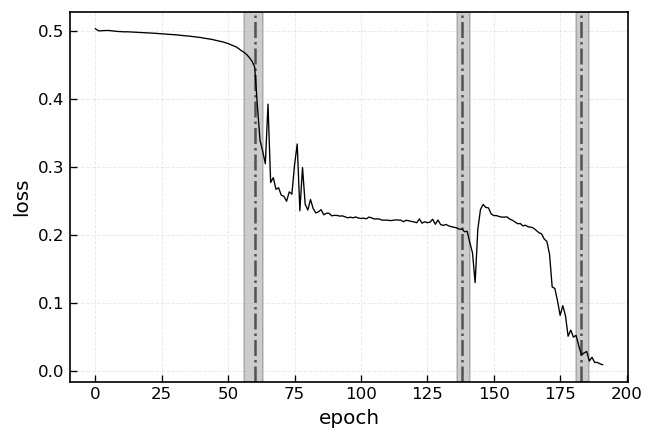

In [61]:
losses = analyzer["full_task_gradients_and_losses"]["losses"]

fig = plt.figure(figsize=(6,4))
ax = fig.add_subplot(111)
ax.plot(losses, c="black", linewidth=.8)
ax.set_xlabel("epoch")
ax.set_ylabel("loss")

for event in learning_events["events"]:
        ax.axvline(event["center_idx"],
               color="black",
               linewidth=1.5,
               alpha=.6,
               linestyle="-.")
        
        ax.axvspan(event["start_idx"],
                   event["end_idx"],
                   color="black",
                   alpha=.2)

# plt.savefig("Figures/Figures_4/learning_windows_loss.png")   
plt.show()

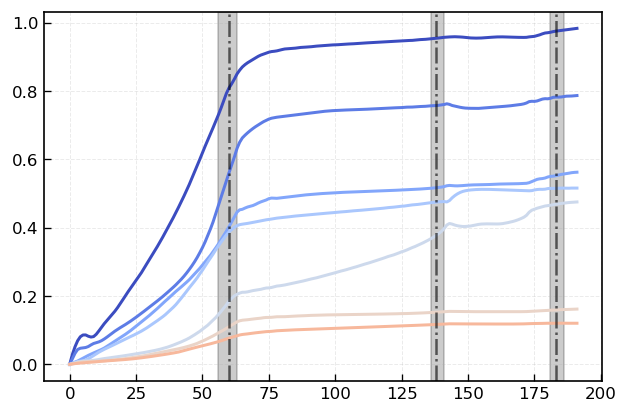

In [ ]:
# track weight change matrix 

fig = plt.figure(figsize=(6,4))
ax = fig.add_subplot(111)
ax.plot(analyzer.rec_singular_values[:,:MAX_RANK])
ax.set_ylabel("singular_values")

for event in learning_events["events"]:
        ax.axvline(event["center_idx"],
               color="black",
               linewidth=1.5,
               alpha=.6,
               linestyle="-.")
        
        ax.axvspan(event["start_idx"],
                   event["end_idx"],
                   color="black",
                   alpha=.2)
        


# plt.savefig("Figures/Figures_4/weight_change_singular_values_with_learning_windows.png")
plt.show()

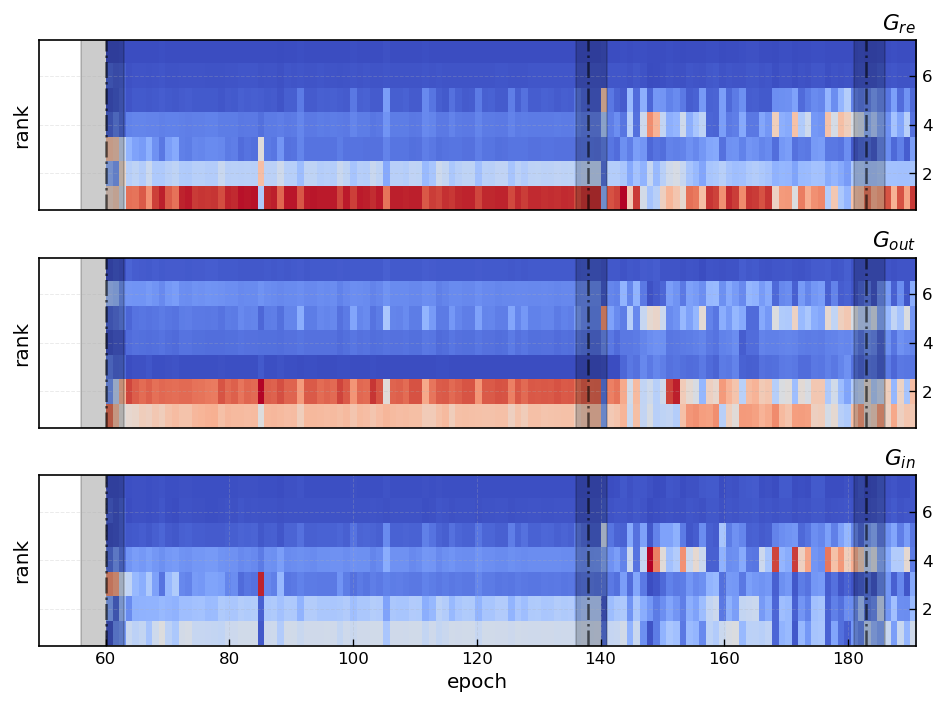

In [59]:
# let's just plot this for starters and see what happens
G_marginal = analyzer["stage_wise_recurrent_gradients"]["G_marginal"]
G_marginal_out = analyzer["stage_wise_recurrent_gradients"]["G_marginal_out"]
G_marginal_in = analyzer["stage_wise_recurrent_gradients"]["G_marginal_in"]

fig, axs = plt.subplots(3, 1, figsize=(8,6))

im = axs[0].imshow(
        G_marginal.T,
        aspect="auto",
        origin="lower",
        extent=[
            centres[0],
            epochs[-1],
            .5,
            MAX_RANK + .5
        ],
        vmin=0,
        vmax=np.nanmax(
            G_marginal
        )
    )

axs[0].set_title(r"$G_{re}$", loc="right")
axs[0].set_xticks([])

im = axs[1].imshow(
        G_marginal_out.T,
        aspect="auto",
        origin="lower",
        extent=[
            centres[0],
            epochs[-1],
            .5,
            MAX_RANK + .5
        ],
        vmin=0,
        vmax=np.nanmax(
            G_marginal_out
        )
    )
axs[1].set_title(r"$G_{out}$", loc="right")
axs[1].set_xticks([])

im = axs[2].imshow(
        G_marginal_in.T,
        aspect="auto",
        origin="lower",
        extent=[
            centres[0],
            epochs[-1],
            .5,
            MAX_RANK + .5
        ],
        vmin=0,
        vmax=np.nanmax(
            G_marginal_in
        )
    )

axs[2].set_title(r"$G_{in}$", loc="right")
axs[2].set_xlabel("epoch")

for ax in axs:
    ax.yaxis.tick_right()

    for event in learning_events["events"]:
        ax.axvline(event["center_idx"],
               color="black",
               linewidth=1.5,
               alpha=.6,
               linestyle="-.")
        
        ax.axvspan(event["start_idx"],
                   event["end_idx"],
                   color="black",
                   alpha=.2)
        
        ax.set_ylabel("rank",
                      rotation=90,
                      labelpad=5)
        
fig.tight_layout()
plt.show()

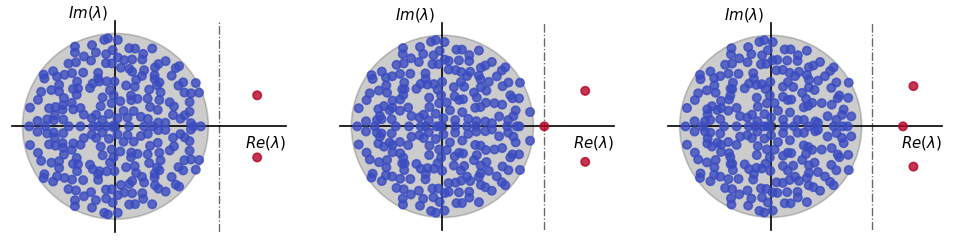

In [60]:
# track eigenvalue spectrum over the windows
fig, axs = plt.subplots(1, 3, figsize=(10, 6))

for idx, event in enumerate(learning_events["events"]):
    
    # plot structure at the end of learning window
    plot_spectrum(model, w_rec=False, mat=A.W_rec[event["end_idx"]], ax=axs[idx])

# plt.savefig("Figures/Figures_4/learning_stage_eigenvalue_spectrum.png")
plt.show()

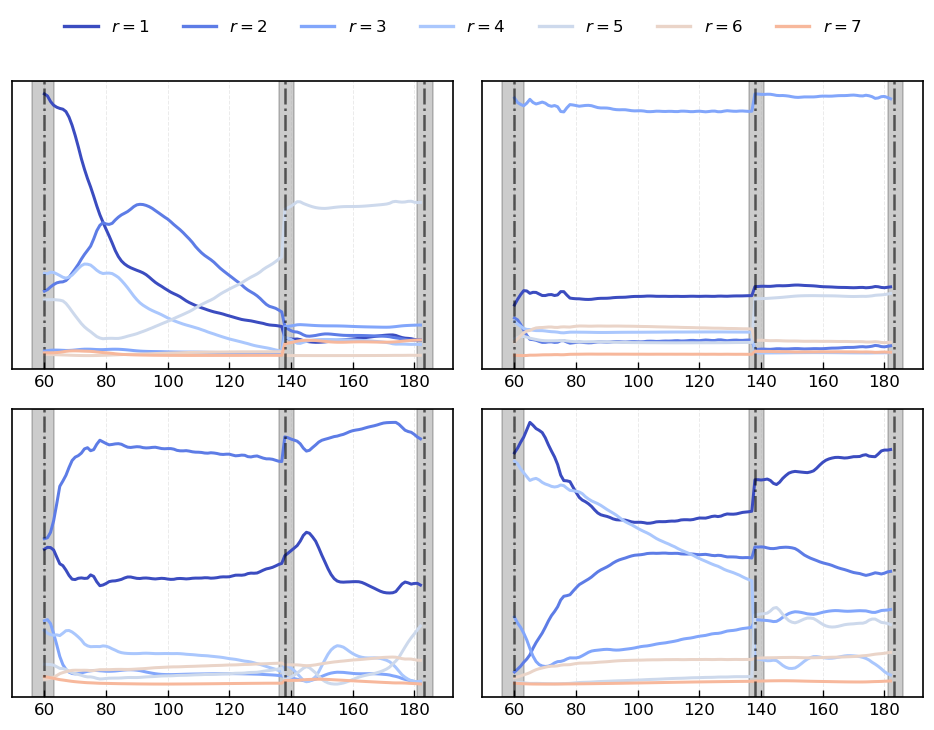

In [ ]:
dWin_marginal = analyzer["stage_wise_I0_gradients"]["dWin_marginal"]
dWout_marginal = analyzer["stage_wise_I0_gradients"]["dWout_marginal"]

from matplotlib.lines import Line2D
colors = get_colors(num_colors=MAX_RANK + 2) # why? This is random. 

fig, axs = plt.subplots(2, 2, figsize=(8, 6))
xvals = range(centres[0], centres[0] + dWin_marginal.shape[0])
axs[0,0].plot(xvals, dWin_marginal[:,0,:])
axs[0,0].set_title(r"$\Delta w_{in, 1}$,in")
axs[0,1].plot(xvals, dWin_marginal[:,1,:])
axs[1,0].plot(xvals, dWout_marginal[:,0,:])
axs[1,1].plot(xvals, dWout_marginal[:,1,:])

for ax in fig.axes:

    for event in learning_events["events"]:
        ax.axvline(event["center_idx"],
               color="black",
               linewidth=1.5,
               alpha=.6,
               linestyle="-.")
        
        ax.axvspan(event["start_idx"],
                   event["end_idx"],
                   color="black",
                   alpha=.2)
        
        ax.set_yticks([])

handles = [
    Line2D(
        [0], [0],
        color=colors[r],
        lw=2,
        label=f"$r={r+1}$"
    )
    for r in range(MAX_RANK)
]

fig.legend(
    handles=handles,
    loc="upper center",
    ncol=MAX_RANK,
    frameon=False,
    bbox_to_anchor=(0.5, 1.02)
)


fig.tight_layout(
    rect=[0, 0, 1, .94]
)

plt.show()


In [ ]:

max_rank = MAX_RANK
dW_in = deepcopy(A.dW_in)
dW_out = deepcopy(A.dW_out)


if dW_in.shape[1] != U_rec_at_centers.shape[1]:
    dW_in = np.swapaxes(dW_in, 1, 2)

if dW_out.shape[1] != U_rec_at_centers.shape[1]:
    dW_out = np.swapaxes(dW_out, 1, 2)

num_inputs = dW_in.shape[-1]
num_outputs = dW_out.shape[-1]


# make nested lists for each input and output direction (not so readable, but extends nicely to different set-ups)
dWin_cumulative = [[] for _ in range(num_inputs)]
dWin_marginal = [[] for _ in range(num_inputs)]

dWout_cumulative = [[] for _ in range(num_outputs)]
dWout_marginal = [[] for _ in range(num_outputs)]




for idx, (start, end) in enumerate(zip(centres[:-1], centres[1:])):

    Win = dW_in[start:end]
    Wout = dW_out[start:end]


    for i in range(end - start):

        for j in range(num_inputs):

            cumulative, marginal = vector_energy_spectrum(
                Win[i, :, j],
                U,
                max_rank
            )

            dWin_cumulative[j].append(
                cumulative
            )

            dWin_marginal[j].append(
                marginal
            )

        for j in range(num_outputs):

            cumulative, marginal = vector_energy_spectrum(
                Wout[i, :, j],
                V,
                max_rank
            )

            dWout_cumulative[j].append(
                cumulative
            )

            dWout_marginal[j].append(
                marginal
            )
            
dWin_cumulative = np.stack(
    [
        np.stack(x)
        for x in dWin_cumulative
    ],
    axis=1
)

dWin_marginal = np.stack(
    [
        np.stack(x)
        for x in dWin_marginal
    ],
    axis=1
)


dWout_cumulative = np.stack(
    [
        np.stack(x)
        for x in dWout_cumulative
    ],
    axis=1
)

dWout_marginal = np.stack(
    [
        np.stack(x)
        for x in dWout_marginal
    ],
    axis=1
)




In [ ]:
# to justify the learning window picture, we want to just see: over the whole training episode how 'spread' is the gradient? Does it only change a handful of directions
# or does it change 


G_rec = A["full_task_gradients_and_losses"]["G_rec"]

eff_ranks = []
for i in range(G_rec.shape[0]):
    _, S, _ = np.linalg.svd(
        G_rec[i,...]
    )

    S2 = S ** 2
    S4 = S ** 4


    eff_ranks.append(
        S2.sum() ** 2 
        / 
        S4.sum()
    ) 

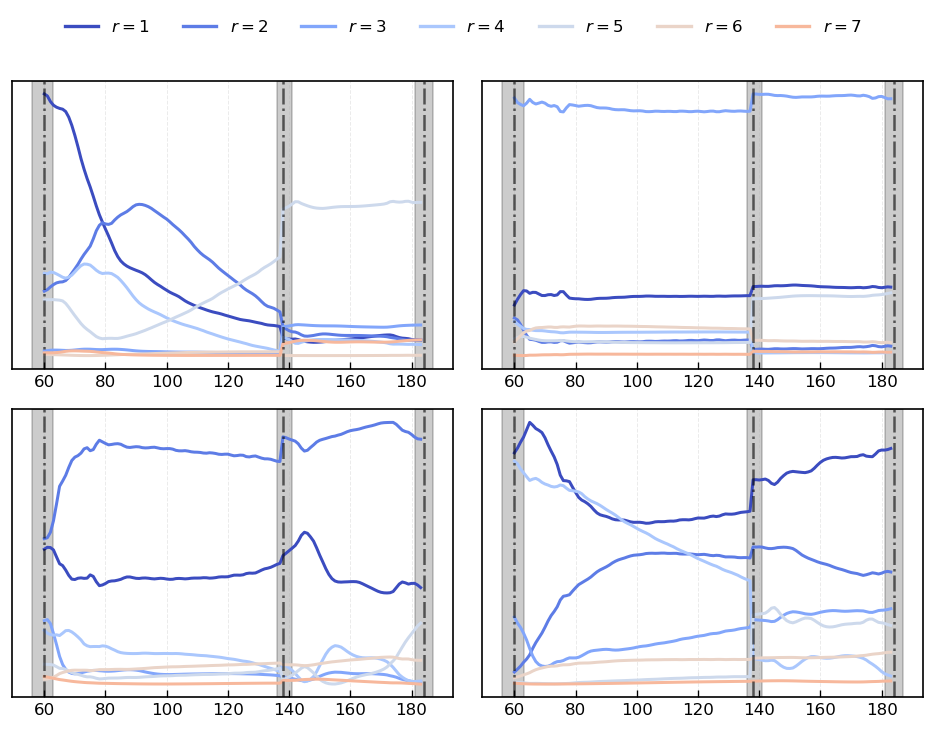

In [ ]:
from matplotlib.lines import Line2D
colors = get_colors(num_colors=max_rank + 2) # why? This is random. 

fig, axs = plt.subplots(2, 2, figsize=(8, 6))
xvals = range(centres[0], centres[0] + dWin_marginal.shape[0])
axs[0,0].plot(xvals, dWin_marginal[:,0,:])
axs[0,1].plot(xvals, dWin_marginal[:,1,:])
axs[1,0].plot(xvals, dWout_marginal[:,0,:])
axs[1,1].plot(xvals, dWout_marginal[:,1,:])

for ax in fig.axes:

    for event in learning_events["events"]:
        ax.axvline(event["center_idx"],
               color="black",
               linewidth=1.5,
               alpha=.6,
               linestyle="-.")
        
        ax.axvspan(event["start_idx"],
                   event["end_idx"],
                   color="black",
                   alpha=.2)
        
        ax.set_yticks([])

handles = [
    Line2D(
        [0], [0],
        color=colors[r],
        lw=2,
        label=f"$r={r+1}$"
    )
    for r in range(max_rank)
]

fig.legend(
    handles=handles,
    loc="upper center",
    ncol=max_rank,
    frameon=False,
    bbox_to_anchor=(0.5, 1.02)
)


fig.tight_layout(
    rect=[0, 0, 1, .94]
)

plt.show()

In [ ]:
G_reuse = []
G_new = []
G_marginal = []
G_marginal_in = []
G_marginal_out = []


for idx, (start, end) in enumerate(zip(centres[:-1], centres[1:])):
    print(idx,
          start,
          end)
    
    U = U_rec_at_centers[idx]
    V = V_rec_at_centers[idx]
    G = G_rec[start:end, ...]
    
    for i in range(G.shape[0]):

      
      
      (re, 
       new, 
       marginal, 
       marginal_in, 
       marginal_out) = recurrent_energy_spectrum(
                                    G[i,...],
                                    U,
                                    V
                        ) 


      G_reuse.append(re)
      G_new.append(new)
      G_marginal.append(marginal)
      G_marginal_in.append(marginal_in)
      G_marginal_out.append(marginal_out)


G_reuse = np.stack(G_reuse)
G_new = np.stack(G_new)
G_marginal = np.stack(G_marginal)
G_marginal_in = np.stack(G_marginal_in)
G_marginal_out = np.stack(G_marginal_out)


0 60 138
1 138 184


In [ ]:
# let's just plot this for starters and see what happens
fig, axs = plt.subplots(3, 1, figsize=(8,6))


im = axs[0].imshow(
        G_marginal.T,
        aspect="auto",
        origin="lower",
        extent=[
            centres[0],
            epochs[-1],
            .5,
            MAX_RANK + .5
        ],
        vmin=0,
        vmax=np.nanmax(
            G_marginal
        )
    )

axs[0].set_title(r"$G_{re}$", loc="right")
axs[0].set_xticks([])

for c in centres:
    ax.axvline(c,
               color="white",
               linewidth=2,
               alpha=.6,
               linestyle="-.")
    
    
    

im = axs[1].imshow(
        G_marginal_out.T,
        aspect="auto",
        origin="lower",
        extent=[
            centres[0],
            epochs[-1],
            .5,
            MAX_RANK + .5
        ],
        vmin=0,
        vmax=np.nanmax(
            G_marginal_out
        )
    )
axs[1].set_title(r"$G_{out}$", loc="right")
axs[1].set_xticks([])

im = axs[2].imshow(
        G_marginal_in.T,
        aspect="auto",
        origin="lower",
        extent=[
            centres[0],
            epochs[-1],
            .5,
            MAX_RANK + .5
        ],
        vmin=0,
        vmax=np.nanmax(
            G_marginal_in
        )
    )

axs[2].set_title(r"$G_{in}$", loc="right")
axs[2].set_xlabel("epoch")

for ax in axs:
    ax.yaxis.tick_right()

    for event in learning_events["events"]:
        ax.axvline(event["center_idx"],
               color="black",
               linewidth=1.5,
               alpha=.6,
               linestyle="-.")
        
        ax.axvspan(event["start_idx"],
                   event["end_idx"],
                   color="black",
                   alpha=.2)
        
        ax.set_ylabel("rank",
                      rotation=90,
                      labelpad=5)
        
fig.tight_layout()
plt.savefig("Figures/Figures_4/simplicity_bias_gradient_energy.png")

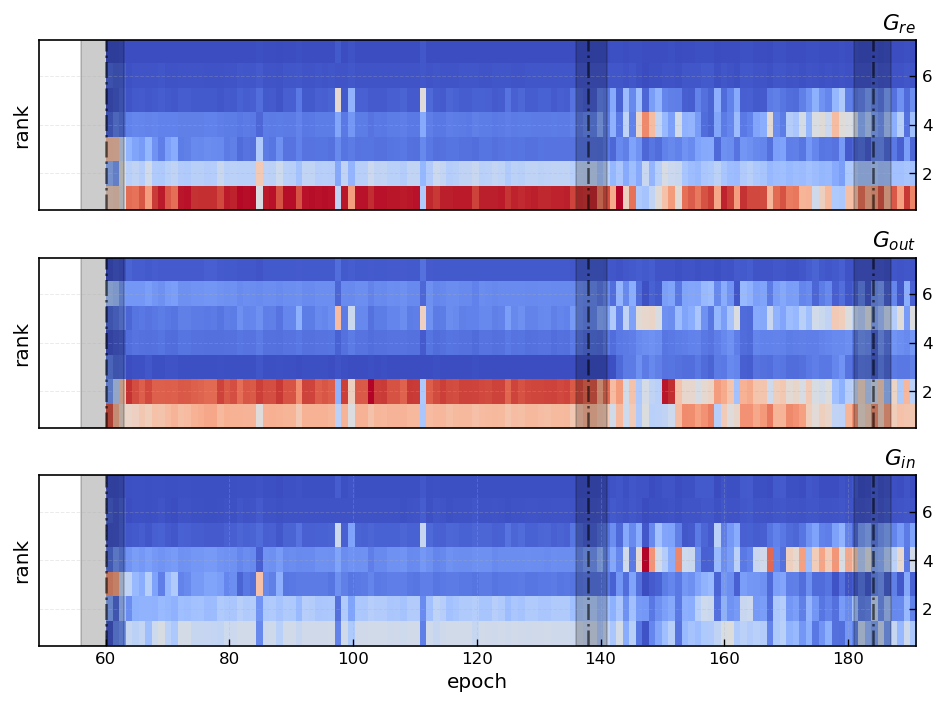

In [110]:
plt.show()

0
1
2


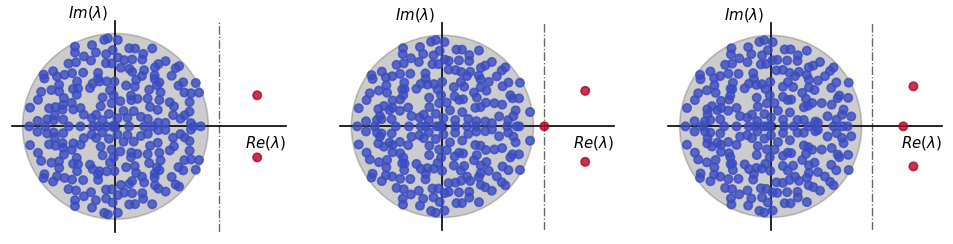

In [111]:
# We might wanna track the eigenvalue structure of the model as it moves through the learning phases:

fig, axs = plt.subplots(1, 3, figsize=(10, 6))

for idx, event in enumerate(learning_events["events"]):
    print(idx)
    
    # plot structure at the end of learning window
    plot_spectrum(model, w_rec=False, mat=A.W_rec[event["end_idx"]], ax=axs[idx])

plt.savefig("Figures/Figures_4/learning_stage_eigenvalue_spectrum.png")
plt.show()

[<Axes3D: >,
 <Axes3D: >,
 <Axes3D: >,
 <Axes3D: >,
 <Axes3D: >,
 <Axes3D: >,
 <Axes3D: >,
 <Axes3D: >,
 <Axes3D: >]

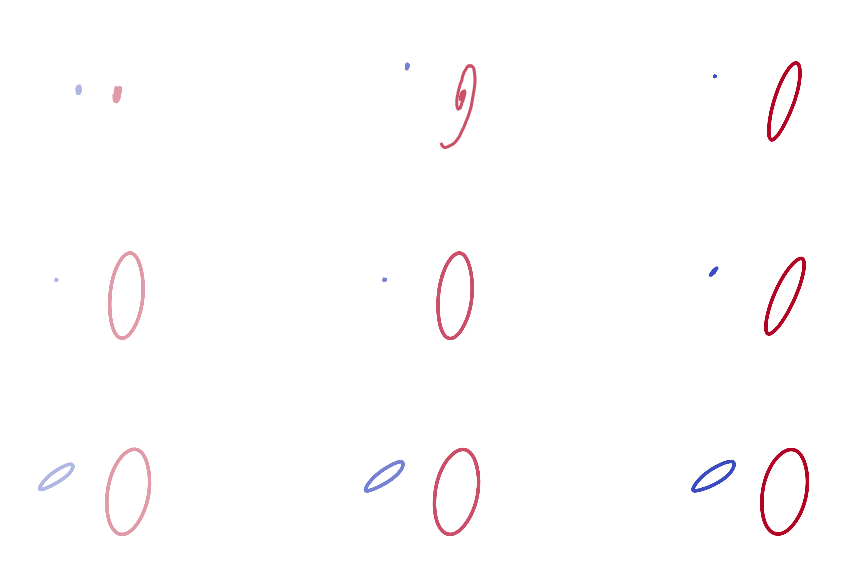

In [ ]:
# let's also get the dynamics at each of these points (do a PCA here?):
from sklearn.decomposition import PCA 
rates = A["full_task_gradients_and_losses"]["rates"]
trnst = 50
with plotstyle.context("inputs", 2):

    fig = plt.figure(figsize=(10, 6))
    counter = 0
    for idx, event in enumerate(learning_events["events"]):

        for event_type in ["start_idx", "center_idx", "end_idx"]
        ax = fig.add_subplot(3, 3, counter + 1, projection="3d")
        pca = PCA(n_components=3)
        rates_ = rates[event["start_idx"]].reshape(-1, 256)
        pca.fit(rates_)
        rates_ = pca.transform(rates_)
        rates_ = rates_.reshape(2, 200, -1)
        ax = fig.add_subplot(3, 3, counter + 1, projection="3d")
        for i in range(rates_.shape[0]):
            ax.plot(rates_[i, trnst:, 0],
                    rates_[i, trnst:, 1],
                    rates_[i, trnst:, 2],
                    alpha=.4)
            
        counter += 1
            
        pca = PCA(n_components=3)
        rates_ = rates[event["center_idx"]].reshape(-1, 256)
        pca.fit(rates_)
        rates_ = pca.transform(rates_)
        rates_ = rates_.reshape(2, 200, -1)
        ax = fig.add_subplot(3, 3, counter + 1, projection="3d")
        for i in range(rates_.shape[0]):
            ax.plot(rates_[i, trnst:, 0],
                    rates_[i, trnst:, 1],
                    rates_[i, trnst:, 2],
                    alpha=.7 
                    )
        
        counter += 1
            
        pca = PCA(n_components=3)
        rates_ = rates[event["end_idx"]].reshape(-1, 256)
        pca.fit(rates_)
        rates_ = pca.transform(rates_)
        rates_ = rates_.reshape(2, 200, -1)
        ax = fig.add_subplot(3, 3, counter + 1, projection="3d")
        for i in range(rates_.shape[0]):
            ax.plot(rates_[i, trnst:, 0],
                    rates_[i, trnst:, 1],
                    rates_[i, trnst:, 2],
                    alpha=1
                    )
            
        counter += 1

    for ax in fig.axes:
            
        ax.set_xticklabels([])
        ax.set_yticklabels([])
        ax.set_zticklabels([])
        ax.grid(False)
        ax.axis('off')

# plt.savefig("Figures/Figures_4/stagewise_pca_dynamics.png")
plt.savefig("Figures/Figures_4/stagewise_pca_dynamics_axis_off_start_middle_end.png")
plt.show()



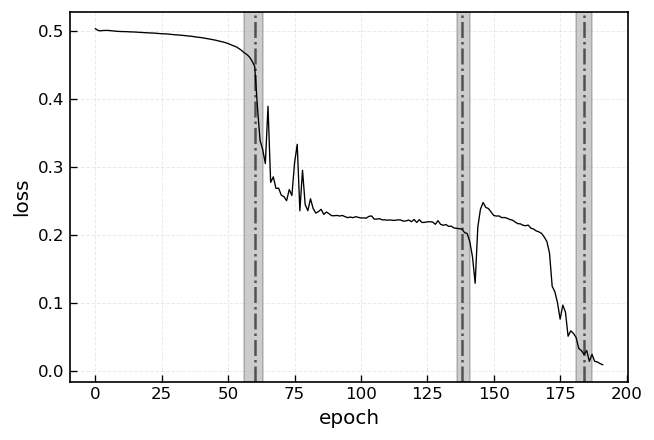

In [113]:
losses = A["full_task_gradients_and_losses"]["losses"]

fig = plt.figure(figsize=(6,4))
ax = fig.add_subplot(111)
ax.plot(losses, c="black", linewidth=.8)
ax.set_xlabel("epoch")
ax.set_ylabel("loss")

for event in learning_events["events"]:
        ax.axvline(event["center_idx"],
               color="black",
               linewidth=1.5,
               alpha=.6,
               linestyle="-.")
        
        ax.axvspan(event["start_idx"],
                   event["end_idx"],
                   color="black",
                   alpha=.2)

plt.savefig("Figures/Figures_4/learning_windows_loss.png")   
plt.show()


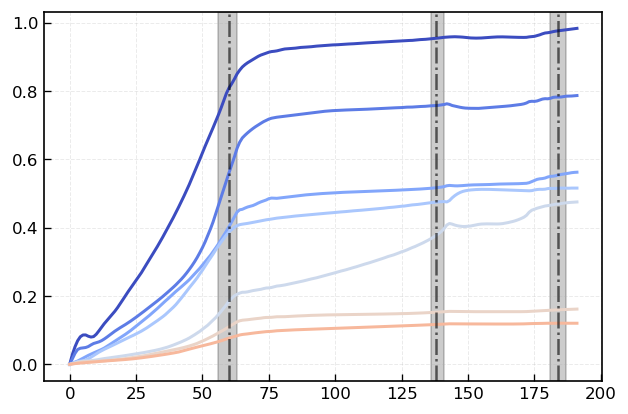

In [115]:
fig = plt.figure(figsize=(6,4))
ax = fig.add_subplot(111)
ax.plot(A.rec_singular_values[:,:MAX_RANK])

for event in learning_events["events"]:
        ax.axvline(event["center_idx"],
               color="black",
               linewidth=1.5,
               alpha=.6,
               linestyle="-.")
        
        ax.axvspan(event["start_idx"],
                   event["end_idx"],
                   color="black",
                   alpha=.2)

plt.savefig("Figures/Figures_4/weight_change_singular_values_with_learning_windows.png")
plt.show()

In [ ]:
# we also wanna know how the gradients affect and are contrained by the input/output directions.
# For a subcritically initialized model, the initial dynamics should lie primarily in the span of the input vectors



In [ ]:
def recurrent_energy_spectrum(G, U, V, max_rank=MAX_RANK):

    """
    Tangent-space decomposition of the gradients G in line with our 
    definition of the definition of the simplicity bias. Intended
    to illicit the 'gradient-trapping' phenomenon.

    The 're-used' portion is the part of the gradient that lies in the
    tangent space of the existing weight change at the start of the
    learning window, i.e.

        G_re = P_U G + G P_V - P_U G P_V

    We also take: 

        G_out = P_U G 
        G_in = G P_V

    These also have nice interpretations:
        
        G_out are the directions in which the gradient wants to modify the already existing output directions of the weight change
        G_in are the directions of the forward activity due to the weight change that are contributing to the gradient. In our lingo: this is the quantity
        that describes how much the existing structure is 'trapping' or 'hogging' the gradient.  
        
        
        the directions in which the forward activity due to the weight change is trapping the gradient

    So, hypothetically, gradient trapping should reveal itself in large G P_Vs for only a handful of right-singular vectors.
    At the same time, learning events should then be preceeded/accompanied by large excursions of P_U G. 

    In other words:
        large G P_V -> gradients lie primarily in the directions of the forward acticity due to already existing structure -> gradient trapping/hogging
        large P_U G -> gradients modify the weight change matrix in the output


    whereas the 'new' portion is simply the remaining part of the gradient 
    (the part that lies along the manifold normal). I.e.

        G_new = (I-P_U) G (I-P_V)

    """

    eps = 1e-12
    N = G.shape[0]
    I = np.eye(N)

    # We quantify the two parts as percentages of the total gradient norm
    # i.e. G_re + G_new = 1

    norm = (
        np.linalg.norm(
            G,
            "fro"
        ) ** 2
        + eps
    )

    reuse = np.zeros(max_rank)
    new = np.zeros(max_rank)
    in_ = np.zeros(max_rank)
    out = np.zeros(max_rank)

    for r in range(1, max_rank + 1):

        Ur = U[:, :r]
        Vr = V[:, :r]

        PU = Ur @ Ur.T
        PV = Vr @ Vr.T

        G_in = G @ PV
        G_out = PU @ G
        Greuse = G_in + G_out - PU @ G @ PV
        Gnew = (I - PU) @ G @ (I - PV)


        # taking norms means all of these are cumulative
        in_[r - 1] = (
            np.linalg.norm(
                G_in,
                "fro"
            ) ** 2
            / norm
        )

        out[r - 1] = (
            np.linalg.norm(
                G_out,
                "fro"
            ) ** 2
            / norm
        )

        reuse[r - 1] = (
            np.linalg.norm(
                Greuse,
                "fro"
            ) ** 2
            / norm
        )

        new[r - 1] = (
            np.linalg.norm(
                Gnew,
                "fro"
            ) ** 2
            / norm
        )

    marginal = np.empty_like(reuse)
    marginal_in = np.empty_like(in_)
    marginal_out = np.empty_like(out)

    # most of the time, we'll be more interested in the marginals
    # since that will help us pry apart effects along the governing
    # singular directions of the weight change matrix

    marginal[0] = reuse[0]
    marginal[1:] = reuse[1:] - reuse[:-1]

    marginal_in[0] = in_[0]
    marginal_in[1:] = in_[1:] - in_[:-1]

    marginal_out[0] = out[0]
    marginal_out[1:] = out[1:] - out[:-1]

    return (
            reuse, 
            new, 
            marginal, 
            marginal_in,
            marginal_out
        )

A.add(

    "recurrent_energy_spectrum",
    lambda: recurrent_energy_spectrum(
        G=G,
    ), 
    overwrite=True
)


In [154]:
def vector_energy_spectrum(X, Q, max_rank):
      
    """Analogous to above, except x is a vector and Q
    is a nested set of directions, i.e.
    span{Q} = (Q1, Q2, ...)

    e.g. Q is the subspace spanned by the singular 
    directions of the weight change matrix truncated
    at different ranks
    """

    eps = 1e-12
    norm = np.linalg.norm(X) ** 2 + eps

    cumulative = np.zeros(max_rank)

    for r in range(1, max_rank + 1):

        Qr = Q[:, :r]
        proj = Qr @ (Qr.T @ X)
        cumulative[r-1] = np.linalg.norm(proj) ** 2 / norm
        
    marginal = np.empty_like(cumulative)
    marginal[0] = cumulative[0]
    marginal[1:] = cumulative[1:] - cumulative[:-1]

    return cumulative, marginal

def split_hidden_vectors(X, N):
        """
        Convert an input/output matrix into:
            [n_vectors, N] 
        """

        X = to_numpy(X)
        if X.ndim == 1:
            assert A.shape[0] == N

        # we want X.shape = [in_dim, N] -> w_in & w_out can be treated the same way
        if X.shape[0] == N:
            return X.T

        if X.shape[-1] == N:
            return X
